# **Relationship Between Swimming and Running Performance in Triathletes**

**Authors:** Elena Liaño Rengel and Varvara Gkiouzepa Petropoulou

**Public project website:** GitHub Pages: https://elenaliano.github.io/

**Course:** CMPS3160 - Intro to Data Science

### **Project Description**

This project focuses on the relationship between swimming and running performance in triathlon. More specifically, whether athletes who perform well in swimming also tend to perform well in running, and if this relationship differs across gender and age groups.

To do this, we will work with multiple datasets. For this milestone, our main dataset contains more than 840,000 IRONMAN 70.3 race results from 2004 to 2020. It includes individual race splits, athlete characteristics, and competition information. All of this will allow us to compare performances across different groups.

We aim to understand the strength of this relationship and identify patterns that we could investigate further through the following data cleaning, exploratory analysis, and visualizations.

This project is significant to us since we are athletes in running and swimming respectively. We are interested to see the results of the correlation of both sports performance and hopefully apply them to our training.

#### Collaboration Plan

The team plan is to meet once a week or as needed to evaluate progress, work on research questions, and resolve problems. Google Drive is used to have a shared space for the team's documents, and Google Colab to write and run Python code. The most common form of communication will be WhatsApp.

We will be dividing the work based on each Milestone's requirements while considering the stronger aspects of each team member. We both worked on the data collection. Our preference is to work in person when deciding on roles and make sure we are communicating ideas freely while discussing our options. We will be using our shared Drive folder to include any drafts and ideas.

### **Datasets**

Dataset 1: [Ironman 70.3 (2004–2020)](https://www.kaggle.com/datasets/aiaiaidavid/ironman-703-race-data-between-2004-and-2020)

- To what extent is swimming performance associated with running performance among triathletes?

- Does the relationship between swimming and running performance vary across age groups, gender (male or female), and competitive status (professionals or amateurs) within triathletes?

Dataset 2: [2019 Ironman World Championship](https://www.kaggle.com/datasets/andyesi/2019-ironman-world-championship-results)

- Is the relationship between swimming and running performance different among professional triathletes and age-group competitors?

Dataset 3: [Multi-Sport Race Result Data](https://github.com/matsubo/triathlon-result-data)

- Does the strength of the association between swimming and running performance differ across triathlon race distances?

- Do athletes tend to exhibit more balanced swimming and running performances in shorter or longer triathlon events?

## **1. Extract: Loading, and Inspecting the Data**

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

### Load Dataset 1

We aqcuired this dataset from kaggle and used its import reccomendation for downloading via kagglehub.

In [2]:
!pip install kagglehub
import kagglehub

# We download the latest version from the webpage of our dataset
path = kagglehub.dataset_download(
    "aiaiaidavid/ironman-703-race-data-between-2004-and-2020"
)

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'ironman-703-race-data-between-2004-and-2020' dataset.
Path to dataset files: /kaggle/input/ironman-703-race-data-between-2004-and-2020


In [3]:
df_raw = pd.read_csv(Path(path) / "Half_Ironman_df6.csv")

display(df_raw.head())
df_raw.info()

,Gender,AgeGroup,AgeBand,Country,CountryISO2,EventYear,EventLocation,SwimTime,Transition1Time,BikeTime,Transition2Time,RunTime,FinishTime
0,M,40-44,40,Andorra,AD,2019,IRONMAN 70.3 South American Championship Bueno...,1679,119,9107,95,5515,16514
1,M,45-49,45,Andorra,AD,2019,IRONMAN 70.3 South American Championship Bueno...,2070,177,9160,132,6070,17609
2,M,45-49,45,Andorra,AD,2020,IRONMAN 70.3 Bariloche,1667,161,9891,122,5190,17031
3,M,45-49,45,Andorra,AD,2019,IRONMAN 70.3 World Championship,1750,183,10363,160,5071,17527
4,M,40-44,40,Andorra,AD,2019,IRONMAN 70.3 World Championship,2063,182,10065,142,5556,18008


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 840075 entries, 0 to 840074
Data columns (total 13 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   Gender           840075 non-null  object
 1   AgeGroup         840075 non-null  object
 2   AgeBand          840075 non-null  int64 
 3   Country          840075 non-null  object
 4   CountryISO2      840075 non-null  object
 5   EventYear        840075 non-null  int64 
 6   EventLocation    840075 non-null  object
 7   SwimTime         840075 non-null  int64 
 8   Transition1Time  840075 non-null  int64 
 9   BikeTime         840075 non-null  int64 
 10  Transition2Time  840075 non-null  int64 
 11  RunTime          840075 non-null  int64 
 12  FinishTime       840075 non-null  int64 
dtypes: int64(8), object(5)
memory usage: 83.3+ MB


## **2. Transform: Cleaning and Reorganizing the Data**



We will do some transformation to our table according to tidy data.

We want to rename our columns in a way that it will be easier for reading and understanding. For the variables measured in seconds, SwimTime, Transition1Time, BikeTime, Transition2Time, RunTime, FinishTime, we will exclude the keyword time for space purposes.

In [4]:
column_names = {
    "Gender": "Gender",
    "AgeGroup": "Age_Group",
    "AgeBand": "Age_Band",
    "Country": "Country",
    "CountryISO2": "Country_Code",
    "EventYear": "Year",
    "EventLocation": "Event",
    "SwimTime": "Swim",
    "Transition1Time": "Transition_1",
    "BikeTime": "Bike",
    "Transition2Time": "Transition_2",
    "RunTime": "Run",
    "FinishTime": "Finish"
}

df = df_raw.rename(columns=column_names).copy()

df["Gender"] = df["Gender"].replace({
    "M": "Male",
    "F": "Female"
})

df["Event"] = (
    df["Event"]
    .str.replace(r"(?i)^IRONMAN 70\.3\s*", "", regex=True)
    .str.strip(" -,:")
)

In order for our data sets to be more readable, we also notice that "IRONMAN 70.3" is part of 'Event' for each row, so we strip it. Since this dataset only includes Ironman 70.3, we are more interested in seeing the place of the event or if it is a world champioship or not.

Moreover, we sort the values according to event and year so that it is easier to manipulate.

###Age Group Cleaning and Transformation

In this part, we focus on the `Age_Group` column. Since this variable contains age intervals stored as strings, we can't use it directly in numerical calculations. Additionally, some observations have an age group of "00", which identifies professional athletes. We wanted to address both issues.

First, we created a Boolean column, `Is_Pro`, to identify professional athletes. Then, we created a new column called `Age_Group_Mean` by calculating the midpoint of each age interval. For example, athletes in the 30–34 age group are assigned a value of 32. This gives us a numerical representation of the age groups that can be used more easily in calculations and visualizations. For professional athletes, we replaced the resulting zero values with `NaN`, since we do not know their ages.

Finally, we placed `Age_Group_Mean` next to `Age_Group` and removed `Age_Band`, because it's not necessary for our analysis.

We recognize that `Age_Group_Mean` does not represent the actual or average age of the athletes within each group, but we will use it as midpoint of their age interval. For that reason, we decided to keep the original `Age_Group` column to also preserve the original information.

In [5]:
df["Is_Pro"] = df["Age_Group"] == "00" # Identify professional athletes

df["Age_Group_Mean"] = (
    df["Age_Group"]
    .str.split("-", expand=True)[[0, 1]]
    .astype(float)
    .mean(axis=1)
    .round()
    .astype("float")
)

df["Age_Group_Mean"] = df["Age_Group_Mean"].replace(0, np.nan)

df.insert(
    df.columns.get_loc("Age_Group") + 1,
    "Age_Group_Mean",
    df.pop("Age_Group_Mean")
)

df = df.drop(columns=["Age_Band"])

display(df[["Age_Group", "Age_Group_Mean"]].head(10))

,Age_Group,Age_Group_Mean
0,40-44,42.0
1,45-49,47.0
2,45-49,47.0
3,45-49,47.0
4,40-44,42.0
5,35-39,37.0
6,50-54,52.0
7,35-39,37.0
8,40-44,42.0
9,25-29,27.0


## **3. Validate: Checking Data Quality**

### Data Validation and Duplicate Handling

We also checked the dataset for missing values, non-positive race times, and duplicate observations.

We identified 17 exact duplicate rows and examined them before removing the additional copies. Since the dataset does not contain unique athlete identifiers, we cannot determine with certainty whether these records represent duplicated entries or different athletes with identical recorded characteristics and times.


In [6]:
print("Missing values:")
print(df.isna().sum()) # We check for missing values

time_cols = [
    "Swim", "Transition_1", "Bike",
    "Transition_2", "Run", "Finish"
]

print("\nNon-positive times:")
print((df[time_cols] <= 0).sum()) # We check for invalid times

print("\nDuplicate rows:", df.duplicated().sum()) # We check for duplicate rows

display(df[df.duplicated(keep=False)].sort_values( # We inspect the duplicates
    ["Event", "Year", "Finish"]
))

Missing values:
Gender                0
Age_Group             0
Age_Group_Mean    16611
Country               0
Country_Code          0
Year                  0
Event                 0
Swim                  0
Transition_1          0
Bike                  0
Transition_2          0
Run                   0
Finish                0
Is_Pro                0
dtype: int64

Non-positive times:
Swim            0
Transition_1    0
Bike            0
Transition_2    0
Run             0
Finish          0
dtype: int64

Duplicate rows: 17


,Gender,Age_Group,Age_Group_Mean,Country,Country_Code,Year,Event,Swim,Transition_1,Bike,Transition_2,Run,Finish,Is_Pro
642828,Male,25-29,27.0,United States,US,2009,Augusta,1562,171,9330,124,5779,16966,False
643802,Male,25-29,27.0,United States,US,2009,Augusta,1562,171,9330,124,5779,16966,False
643719,Male,45-49,47.0,United States,US,2009,Augusta,1748,266,9252,258,8354,19878,False
644359,Male,45-49,47.0,United States,US,2009,Augusta,1748,266,9252,258,8354,19878,False
666736,Male,40-44,42.0,United States,US,2010,Augusta,1508,268,9266,298,6036,17376,False
667055,Male,40-44,42.0,United States,US,2010,Augusta,1508,268,9266,298,6036,17376,False
665953,Female,35-39,37.0,United States,US,2010,Augusta,1658,297,11082,477,9134,22648,False
667889,Female,35-39,37.0,United States,US,2010,Augusta,1658,297,11082,477,9134,22648,False
759376,Male,25-29,27.0,United States,US,2013,Boulder,2997,256,10676,201,8893,23023,False
759378,Male,25-29,27.0,United States,US,2013,Boulder,2997,256,10676,201,8893,23023,False


### Validating Total Times

In [7]:
split_cols = [
    "Swim", "Transition_1", "Bike",
    "Transition_2", "Run"
]

calculated_finish = df[split_cols].sum(axis=1) #Total time from race splits

finish_difference = df["Finish"] - calculated_finish # We compare calculated and recorded finish times

print(finish_difference.value_counts().sort_index())

display(
    df.assign(
        Calculated_Finish=calculated_finish,
        Finish_Difference=finish_difference
    )[["Event", "Year", "Finish",
       "Calculated_Finish", "Finish_Difference"]].head()
)

inconsistent_times = df[finish_difference.abs() > 5] # we identify inconsistent records

print("Inconsistent records:", len(inconsistent_times))
display(inconsistent_times)

-846         1
-2         732
-1       18771
 0      793408
 1       20711
 2        4848
 3        1540
 4          64
Name: count, dtype: int64


,Event,Year,Finish,Calculated_Finish,Finish_Difference
0,South American Championship Buenos Aires,2019,16514,16515,-1
1,South American Championship Buenos Aires,2019,17609,17609,0
2,Bariloche,2020,17031,17031,0
3,World Championship,2019,17527,17527,0
4,World Championship,2019,18008,18008,0


Inconsistent records: 1


,Gender,Age_Group,Age_Group_Mean,Country,Country_Code,Year,Event,Swim,Transition_1,Bike,Transition_2,Run,Finish,Is_Pro
471501,Male,30-34,32.0,Singapore,SG,2017,Bintan,2762,285,16810,423,4449,23883,False


After comparing the recorded finish times with the sum of the five race splits, we can see how that the vast majority of observations matched exactly, while some showed small differences: between -2 and +4 seconds.

However, we identified one observation from Bintan (2017) with a difference of 846 seconds between the recorded finish time and the sum of the splits, which is considerably larger than the others. Since we can't treat small differences as incorrect recordings, we decided to allow up to 5 seconds differences and exclude any observations exceeding this threshold to avoid including potentially unreliable data in our analysis.

### **4. Final Dataset**

After identifying the inconsistencies in our dataset, we can now create the final cleaned table. We will exclude observations whose recorded finish times differ from the sum of their splits by more than 5 seconds, remove exact duplicate rows, and sort the remaining observations by event and year.



In [8]:
df_tidy = df[finish_difference.abs() <= 5].copy()

df_tidy = df_tidy.drop_duplicates()

df_tidy = df_tidy.sort_values(
    ["Event", "Year"]
).reset_index(drop=True)

print("Original records:", len(df_raw))
print("Final records:", len(df_tidy))
print("Remaining duplicates:", df_tidy.duplicated().sum())

display(df_tidy.head())
df_tidy.info()

Original records: 840075
Final records: 840057
Remaining duplicates: 0


,Gender,Age_Group,Age_Group_Mean,Country,Country_Code,Year,Event,Swim,Transition_1,Bike,Transition_2,Run,Finish,Is_Pro
0,Male,30-34,32.0,Austria,AT,2014,Aarhus,2034,244,9448,180,5876,17782,False
1,Male,25-29,27.0,Austria,AT,2014,Aarhus,2275,259,10476,145,5956,19111,False
2,Male,50-54,52.0,Austria,AT,2014,Aarhus,2542,403,10002,221,6382,19550,False
3,Male,50-54,52.0,Austria,AT,2014,Aarhus,2828,375,11704,232,8112,23251,False
4,Male,25-29,27.0,Australia,AU,2014,Aarhus,1874,166,9256,138,4833,16267,False


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 840057 entries, 0 to 840056
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Gender          840057 non-null  object 
 1   Age_Group       840057 non-null  object 
 2   Age_Group_Mean  823446 non-null  float64
 3   Country         840057 non-null  object 
 4   Country_Code    840057 non-null  object 
 5   Year            840057 non-null  int64  
 6   Event           840057 non-null  object 
 7   Swim            840057 non-null  int64  
 8   Transition_1    840057 non-null  int64  
 9   Bike            840057 non-null  int64  
 10  Transition_2    840057 non-null  int64  
 11  Run             840057 non-null  int64  
 12  Finish          840057 non-null  int64  
 13  Is_Pro          840057 non-null  bool   
dtypes: bool(1), float64(1), int64(7), object(5)
memory usage: 84.1+ MB


After applying these cleaning steps, our dataset was reduced from 840,075 to 840,057 observations. In total, we excluded one inconsistent race result and removed 17 exact duplicate rows. However, since the dataset does not contain unique athlete identifiers, we cannot be completely certain that these duplicates represent repeated entries or different athletes with identical recorded information. The final table retains the variables needed for our research questions and is now ready for exploratory data analysis.

### Gender-Based Subsets

We will split our data set into two. One set for women and one set for men. Since gender plays a big role in performance, we can compare the relationship in running and swimming for men and women seperately. We also reset the index so that the rows are numbered consecutively. But will keep the complete dataset for our overall analysis.


In [9]:
print("Gender categories:", df["Gender"].unique()) #data validation to check gender categories

#We create gender subsets
men_df = df_tidy[df_tidy["Gender"] == "Male"].copy()
women_df = df_tidy[df_tidy["Gender"] == "Female"].copy()

men_df = men_df.reset_index(drop=True)
women_df = women_df.reset_index(drop=True)

print("Men's dataset:", men_df.shape)
print("Women's dataset:", women_df.shape)

display(men_df.head())
display(women_df.head())

Gender categories: ['Male' 'Female']
Men's dataset: (635666, 14)
Women's dataset: (204391, 14)


,Gender,Age_Group,Age_Group_Mean,Country,Country_Code,Year,Event,Swim,Transition_1,Bike,Transition_2,Run,Finish,Is_Pro
0,Male,30-34,32.0,Austria,AT,2014,Aarhus,2034,244,9448,180,5876,17782,False
1,Male,25-29,27.0,Austria,AT,2014,Aarhus,2275,259,10476,145,5956,19111,False
2,Male,50-54,52.0,Austria,AT,2014,Aarhus,2542,403,10002,221,6382,19550,False
3,Male,50-54,52.0,Austria,AT,2014,Aarhus,2828,375,11704,232,8112,23251,False
4,Male,25-29,27.0,Australia,AU,2014,Aarhus,1874,166,9256,138,4833,16267,False


,Gender,Age_Group,Age_Group_Mean,Country,Country_Code,Year,Event,Swim,Transition_1,Bike,Transition_2,Run,Finish,Is_Pro
0,Female,45-49,47.0,Canada,CA,2014,Aarhus,1988,292,10904,154,5042,18380,False
1,Female,45-49,47.0,Canada,CA,2014,Aarhus,2154,419,13684,319,8080,24656,False
2,Female,35-39,37.0,Switzerland,CH,2014,Aarhus,2506,390,10763,293,7046,20998,False
3,Female,00,NaN,Germany,DE,2014,Aarhus,1973,205,9361,131,5306,16976,True
4,Female,00,NaN,Germany,DE,2014,Aarhus,1787,170,9989,116,5068,17130,True


## **4.1 Tidy data justification**

After cleaning and validating our data, we can evaluate whether our final table follows the principles of tidy data.

Our original dataset was already relatively well structured, so we decided to preserve its overall format while improving consistency and data quality.

The final dataset satisfies the three principles of tidy data:

1. **Each variable forms a column.** Athlete characteristics (gender, age group, and country), event information (year and location), and performance measurements (swimming, cycling, running, transitions, and finish times) are stored in separate columns.

2. **Each observation forms a row.** Every row represents one athlete's result in a particular IRONMAN 70.3 race.

3. **Each type of observational unit forms a table.** All observations represent individual race results, so there is no need to separate different types of observations into additional tables.

We also retained both `Age_Group` and `Age_Group_Mean`, allowing us to preserve the original age intervals while having a numerical approximation available for analysis.

Finally, although we created separate male and female subsets to facilitate comparisons, we kept the complete dataset as our main tidy table. This allows us to analyze the relationship between swimming and running performance both overall and within each gender group.

## **4.2 Challenges and Limitations**

### **Challenges**

- Unknown exact ages: We only know the athletes' age intervals, not their actual ages.

- Age Group data type: Age_Group was stored as an object, which made direct numerical calculations difficult.

- Professional athletes: The value "00" represents professionals but not their age.

- Duplicate rows: We identified and removed 17 duplicates, although we cannot confirm they represent the same athletes.

- Inconsistent finish times: One observation had a discrepancy of 846 seconds and was excluded.

- Gender-based analysis: In our first approach, we split the dataset into men and women first and then applied all the changes which took much more space than intended



## **5. Exploratory Data Analysis (EDA)**


### 5.1. Summary Statistics

- **Number of results by gender:** To understand the composition of our dataset.
- **Median swimming and running times by gender:** To compare typical performance across groups.
- **Overall Pearson correlation:** To measure the strength of the linear relationship between swimming and running times.
- **Pearson correlation by gender:** To investigate whether this relationship differs between male and female athletes.
- **Pearson correlation for professional athletes:** To examize whether the relationship changes for male and female professional athletes.
- **Pearson correlation by age group:** To explore whether the relationship varies across age categories.

In [10]:
print("Results by gender:")
print(df_tidy["Gender"].value_counts())

print("\nMedian swimming and running times (minutes):")
median_times = df_tidy.groupby("Gender")[["Swim", "Run"]].median() / 60 # Median times by gender, converted to minutes
display(median_times.round(2))

print("\nOverall Pearson correlation:")
pearson = df_tidy["Swim"].corr(df_tidy["Run"])
print("Pearson correlation:", round(pearson, 3)) # Overall swimming-running correlation

print("\nPearson correlation by gender:") # Correlation by gender
for gender, group in df_tidy.groupby("Gender"):
    correlation = group["Swim"].corr(group["Run"], method="pearson")
    print(gender, round(correlation, 3))

Results by gender:
Gender
Male      635666
Female    204391
Name: count, dtype: int64

Median swimming and running times (minutes):


,Swim,Run
Gender,,
Female,39.73,130.03
Male,37.60,120.22



Overall Pearson correlation:
Pearson correlation: 0.491

Pearson correlation by gender:
Female 0.473
Male 0.486


In [11]:
print("Results for professional athletes:\n")

pro_men = men_df[men_df["Age_Group_Mean"].isna()] # We split into professional male and female athletes
pro_women = women_df[women_df["Age_Group_Mean"].isna()]

print("Professional male athletes:", len(pro_men))
print("Professional female athletes:", len(pro_women))
print("Total professional athletes:", len(pro_men) + len(pro_women))

pro_df = pd.concat([pro_men, pro_women])

pearson = pro_df["Swim"].corr(pro_df["Run"], method="pearson") # Overall swimming-running correlation in professional athletes
print("\nPearson correlation by gender:", round(pearson, 3))

print("\nPearson correlation by gender in professional athletes:") # Correlation by gender
for gender, group in pro_df.groupby("Gender"):
    correlation = group["Swim"].corr(group["Run"], method="pearson")
    print(gender, round(correlation, 3))

Results for professional athletes:

Professional male athletes: 10282
Professional female athletes: 6329
Total professional athletes: 16611

Pearson correlation by gender: 0.462

Pearson correlation by gender in professional athletes:
Female 0.257
Male 0.435


We notice that the correlation between male and female professional triathletes has a greater difference than the difference in all triathletes by gender. These results show that female professional triathletes have a weak correlation in swimming and running performance, which differs by almost 0.2 from male professionals. This is particularly interesting to the team, since we both plan to continue in the professional level of our respective sports, running and swimming.

In [12]:
print("Pearson correlation by age group:")

age_correlations = []

for age, group in df_tidy.groupby("Age_Group"):
    if age != "00" and len(group) >= 100:
        correlation = group["Swim"].corr(group["Run"])

        age_correlations.append({
            "Age Group": age,
            "Number of Results": len(group),
            "Pearson Correlation": correlation
        })

age_corr_df = pd.DataFrame(age_correlations)

display(age_corr_df.round(3))

Pearson correlation by age group:


,Age Group,Number of Results,Pearson Correlation
0,18-24,30613,0.465
1,25-29,89218,0.482
2,30-34,137679,0.486
3,35-39,160911,0.476
4,40-44,159567,0.468
5,45-49,119515,0.438
6,50-54,72759,0.420
7,55-59,34112,0.385
8,60-64,13098,0.361
9,65-69,4395,0.329


### Swimming vs. Running by Gender:

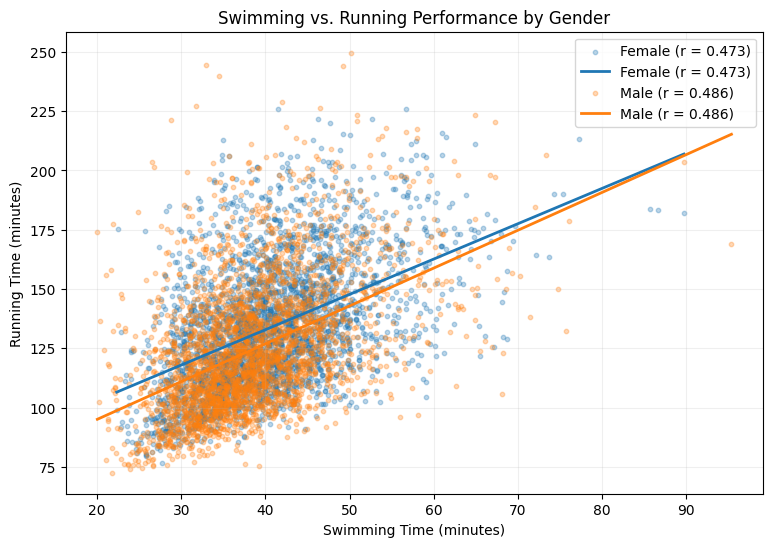

In [13]:
plt.figure(figsize=(9, 6))

for gender, color in [("Female", "tab:blue"), ("Male", "tab:orange")]:

    group = df_tidy[df_tidy["Gender"] == gender]

    correlation = group["Swim"].corr(group["Run"]) # This is the Pearson correlation using all observations

    sample = group.sample(n=3000, random_state=42) # We take a sample for visualization

    plt.scatter(
        sample["Swim"] / 60,
        sample["Run"] / 60,
        alpha=0.3,
        s=10,
        label=f"{gender} (r = {correlation:.3f})"
    )

    slope, intercept = np.polyfit( # We create a linear regression line using all observations
        group["Swim"] / 60,
        group["Run"] / 60,
        1
    )

    x = np.linspace(
        sample["Swim"].min() / 60,
        sample["Swim"].max() / 60,
        100
    )

    plt.plot(
        x,
        slope * x + intercept,
        color=color,
        linewidth=2,
        label=f"{gender} (r = {correlation:.3f})"
    )

plt.xlabel("Swimming Time (minutes)")
plt.ylabel("Running Time (minutes)")
plt.title("Swimming vs. Running Performance by Gender")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

***Important clarification:***  Since our dataset contains over 840,000 observations, we randomly selected 3,000 results per gender to avoid overcrowding the scatter plot. However, the Pearson correlations were calculated using the full dataset to preserve the accuracy of our analysis.

With this scatter plot we can visualize the relationship between swimming and running times for male and female competitors. The regression line shows a positive linear trend, which suggests that slower swimmers tend to have slower running times. However, there is a considerable spread of observations, so we cannot explain running performance based on swimming performance alone or vice versa.

### Correlation by Age Group

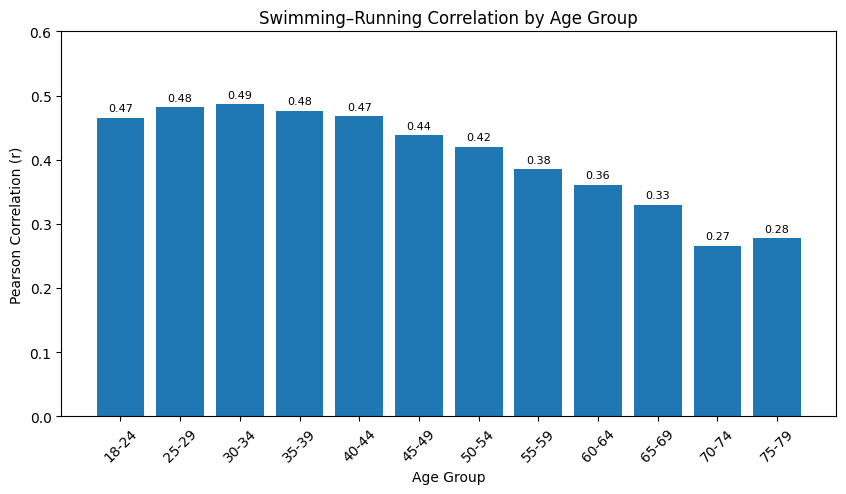

In [14]:
plt.figure(figsize=(10, 5))

bars = plt.bar(
    age_corr_df["Age Group"],
    age_corr_df["Pearson Correlation"]
)

for bar in bars:
    value = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.2f}",
        ha="center",
        fontsize=8
    )

plt.xlabel("Age Group")
plt.ylabel("Pearson Correlation (r)")
plt.title("Swimming–Running Correlation by Age Group")
plt.xticks(rotation=45)
plt.ylim(0, 0.6)
plt.show()

We can see how the Pearson correlation between swimming and running times generally decreases across older age groups, from approximately 0.49 among athletes aged 30–34 to 0.27 among those aged 70–74. This suggests that the linear relationship between the two disciplines may be weaker in older age groups. But we will need to investigate other attribute differences such as sample size, competitive level, and race conditions that could also contribute to this pattern.